[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alanturin-g/Computational_Neuroscience_UNITO_2026/blob/main/Perotti_3_ML_done_partially.ipynb)

In [ ]:
# Yes, again..
# File -> Save a copy in Drive
from google.colab import auth; auth.authenticate_user()
from google.colab import drive; drive.mount('/content/drive')

# Lesson 3 - Machine learning, done right

**Computational Neuroscience 2026/27 · Alan Perotti**

Lesson 2 gave the ideas. Today we write one complete machine learning analysis, one small step at a time, in the correct order. The dataset is the passengers of the Titanic: for each passenger we know a few facts (class, sex, age, ...) and whether they survived. The task is to predict survival.

Nothing here is new: every step applies a rule from the "Good practices" slide of Lesson 2. The new part is that you see each rule written as code.

---

# Part 0 - The tools

> **What we do:** import the libraries.
>
> **Why:** Python tools live in libraries. We load them once, at the top, so that the rest of the notebook can use them.

We import everything at the top, as good practice. You do not need to understand each line now: we meet every tool when we use it, and we say what it does at that moment.

- `numpy`, `pandas`: numbers and tables
- `matplotlib`, `seaborn`: plots
- `train_test_split`: splits the data in train and test
- `StratifiedKFold`, `RepeatedStratifiedKFold`, `cross_validate`, `cross_val_score`: cross-validation
- `validation_curve`, `GridSearchCV`: look at, and choose, hyperparameters
- `SimpleImputer`, `StandardScaler`, `OneHotEncoder`: preprocessing steps
- `ColumnTransformer`, `make_pipeline`: chain the preprocessing steps and the model
- `KNeighborsClassifier`, `RandomForestClassifier`, `MLPClassifier`, `DummyClassifier`: the models
- `clone`: makes a fresh, unfitted copy of a model
- the `metrics` and `permutation_importance`: measure the results

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_score, validation_curve, GridSearchCV)
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

import warnings
warnings.filterwarnings('ignore')

# Part 1 - Look at the data

> **What we do:** inspect the table: its size, the types of the columns, the missing values, the balance of the classes, the scales.
>
> **Why:** every later choice depends on what we find here. A model fitted on a table we did not understand gives numbers we cannot interpret.

**Rule: look at the data first.** Before any model, we want to know what is in the table: how many rows, what kind of columns, how many missing values, which scales. Every decision later depends on these answers.

## 1.1 Load the data

The Titanic dataset comes with the `seaborn` library. We keep eight columns.

| Column | Meaning |
|---|---|
| `survived` | **the label**: 1 if the passenger survived, 0 if not |
| `pclass` | ticket class: 1, 2 or 3 |
| `sex` | `male` or `female` |
| `age` | age in years |
| `sibsp` | number of siblings or spouses on board |
| `parch` | number of parents or children on board |
| `fare` | the price of the ticket |
| `embarked` | the port where the passenger boarded: `C`, `Q` or `S` |

Each row is one passenger. The task is a **classification** problem: predict `survived` (0 or 1) from the other seven columns.

In [10]:
# Load the Titanic table from the seaborn library (needs an internet connection)
titanic = sns.load_dataset('titanic')
# Keep only the columns we need: the label (survived) and 7 features
df = titanic[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']]
# Show the first 5 rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


## 1.2 How big is it, and what is in it?

`shape` gives (rows, columns). `info()` lists each column with its type and the number of values that are **not** missing.

In [11]:
# shape = (number of rows, number of columns)
print("Shape (rows, columns):", df.shape)
print()
# info() lists every column with its type and the number of non-missing values
df.info()

Shape (rows, columns): (891, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    object 
 3   age       714 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


**What to notice.** The table has 891 rows. Most columns have 891 non-null values, but `age` has fewer, and `embarked` has two fewer. Some values are missing. Also, `sex` and `embarked` are `object` columns: they contain text, not numbers. Most models cannot use text directly.

## 1.3 How many passengers survived, and how many died?

The label is `survived`. We count how many rows have 0 and how many have 1.

In [12]:
# How many passengers died (0) and survived (1)?
print("Counts:")
print(df['survived'].value_counts())
print()
# The same, as proportions (they sum to 1)
print("Proportions:")
print(df['survived'].value_counts(normalize=True).round(3))

Counts:
survived
0    549
1    342
Name: count, dtype: int64

Proportions:
survived
0    0.616
1    0.384
Name: proportion, dtype: float64


**What to notice.** About 38% of the passengers survived and about 62% died. The classes are not equally frequent, but the imbalance is moderate (in Lesson 2 it was 90/10). This number is important: a model that always answers "died" would be right about 62% of the time. We will use it as a baseline in Part 3.

## 1.4 Which values are missing?

`isna()` marks the missing values, `sum()` counts them per column.

In [13]:
# isna() marks the missing values, sum() counts them for each column
missing = df.isna().sum()
# Show the counts and the percentage of rows affected
print(pd.DataFrame({'missing': missing, 'percent': (missing / len(df) * 100).round(1)}))

          missing  percent
survived        0      0.0
pclass          0      0.0
sex             0      0.0
age           177     19.9
sibsp           0      0.0
parch           0      0.0
fare            0      0.0
embarked        2      0.2


**What to notice.** 177 ages are missing (about 20% of the passengers) and 2 values of `embarked`. What can we do?

1. **Drop the rows** with a missing value. Simple, but we lose 20% of the passengers, and they may not be a random 20%.
2. **Fill the gaps** (this is called **imputation**), for example with the median age.

We choose imputation. But there is a catch: the value we use to fill the gaps (the median) is *learned from the data*. So, by Lesson 2, it must be learned on the **training set only**. For this reason we do not fill anything now. We do it inside the pipeline, in Part 4.

## 1.5 Which scales?

`describe()` gives, for each numeric column, mean, standard deviation, minimum and maximum.

In [14]:
# describe() gives count, mean, std, min, quartiles and max of each numeric column
df.describe().round(1)

,survived,pclass,age,sibsp,parch,fare
count,891.0,891.0,714.0,891.0,891.0,891.0
mean,0.4,2.3,29.7,0.5,0.4,32.2
std,0.5,0.8,14.5,1.1,0.8,49.7
min,0.0,1.0,0.4,0.0,0.0,0.0
25%,0.0,2.0,20.1,0.0,0.0,7.9
50%,0.0,3.0,28.0,0.0,0.0,14.5
75%,1.0,3.0,38.0,1.0,0.0,31.0
max,1.0,3.0,80.0,8.0,6.0,512.3


**What to notice.** The columns live on very different scales: `pclass` goes from 1 to 3, `age` from under 1 to 80, `fare` from 0 to more than 500. Models based on distances (KNN) and models trained by gradient descent (MLP) would be dominated by `fare`. We will rescale in Part 4.

## 1.6 A first look at the relation with the label

We compute the share of survivors for each value of `sex` and of `pclass`.

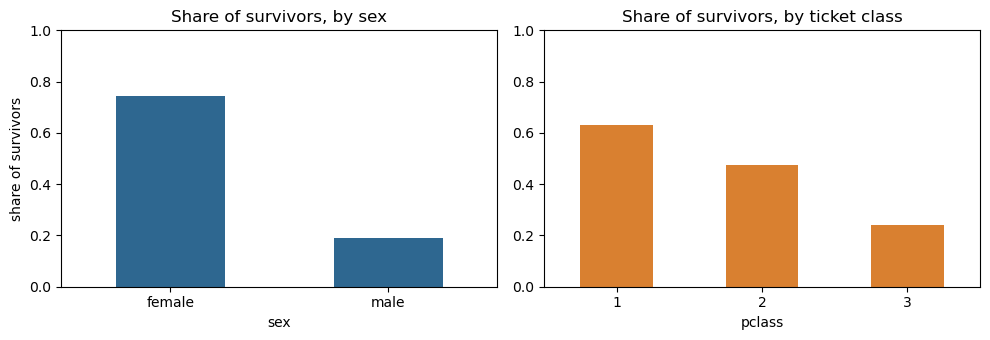

In [15]:
# Left: share of survivors for each sex. Right: for each ticket class
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

# The mean of a 0/1 column is the share of ones, here the share of survivors
df.groupby('sex')['survived'].mean().plot.bar(ax=axes[0], rot=0, color='#2E6790')
axes[0].set_title('Share of survivors, by sex')
axes[0].set_ylabel('share of survivors')
axes[0].set_ylim(0, 1)

df.groupby('pclass')['survived'].mean().plot.bar(ax=axes[1], rot=0, color='#D98030')
axes[1].set_title('Share of survivors, by ticket class')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**What to notice.** Women and first-class passengers survived much more often. So `sex` and `pclass` carry information about the label, and a model has something to learn. This is a description of the data: it does not say *why* (more on this in Part 9).

## 1.7 Separate the features from the label

As in Lesson 2: `X` is the table of features, `y` is the label. We also write down which columns are numeric and which are categorical, because the two kinds need different preprocessing.

`pclass` is a number with an order (1st, 2nd, 3rd), so we treat it as numeric.

We do **not** modify `X` here: it still contains missing values and text. That is on purpose.

In [16]:
# X: the features (every column except the label). y: the label to predict
X = df.drop(columns='survived')
y = df['survived']

# Numeric columns and categorical (text) columns need different preprocessing
numeric_cols = ['pclass', 'age', 'sibsp', 'parch', 'fare']
categorical_cols = ['sex', 'embarked']

print("X:", X.shape, "| y:", y.shape)

X: (891, 7) | y: (891,)


# Ok, then what?